Moved to snakemake!

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import yaml
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# Arial font
matplotlib.rcParams['font.sans-serif'] = "Arial"
matplotlib.rcParams['font.family'] = "sans-serif"

import warnings
warnings.filterwarnings("ignore")

In [2]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/'
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# Prepare the Data

In [3]:
# Define data
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts_filtered.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

In [4]:
# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

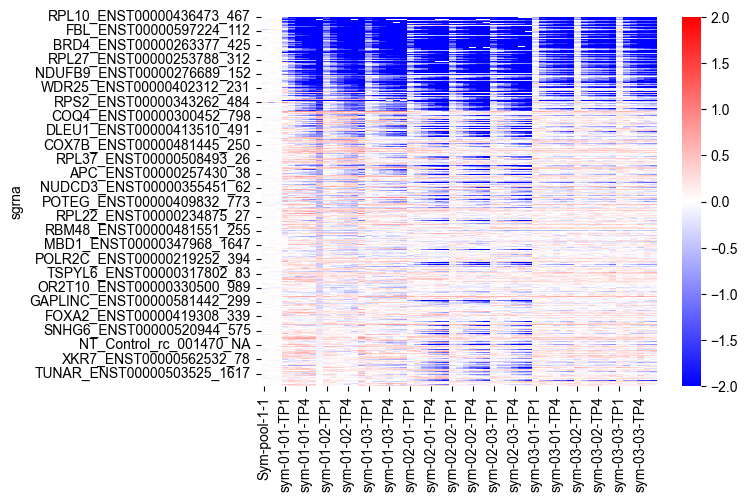

In [5]:
# sanity check
sns.heatmap(l2fc, cmap='bwr', center=0, vmin=-2, vmax=2); 

In [6]:
# annotate
tab = l2fc.iloc[:, 3:].T
tab['time'] = [x.split('-')[-1] for x in tab.index]
tab['replicate'] = [x.split('-')[2] for x in tab.index]
tab['cell_line'] = [cell_line_dict[x.split('-')[1]] for x in tab.index]

In [9]:
cell_line = list(cell_line_dict.values())[0]

In [10]:
# get scores and cluster assignments
scores = pd.read_csv(f"../results/timecourse/timecourse_clusters_{cell_line}.csv", index_col=0)
# get best representing guides for each cluster
tops = pd.read_csv(f"../results/timecourse/timecourse_topgenes_{cell_line}.csv", index_col=0)

In [11]:
scores

,label,dtw,score
sgrna,,,
RPL10_ENST00000436473_467,0,0.230004,1.469658
RAN_ENST00000535090_324,0,0.100096,2.301621
ACTG1_ENST00000573283_1731,0,0.182751,1.699633
RPL14_ENST00000416518_279,0,0.542985,0.610673
CCT8_ENST00000286788_1903,0,0.145949,1.924499
...,...,...,...
NT_Control_rc_001028_NA,4,0.701556,0.354455
RPS23_ENST00000512493_177,3,0.776879,0.252471
EGFLAM-AS1_ENST00000508986_53,2,0.491966,0.709346


In [17]:
scores.sort_values(['label', 'dtw'], inplace=True)

In [19]:
df = l2fc.loc[scores.index].copy()

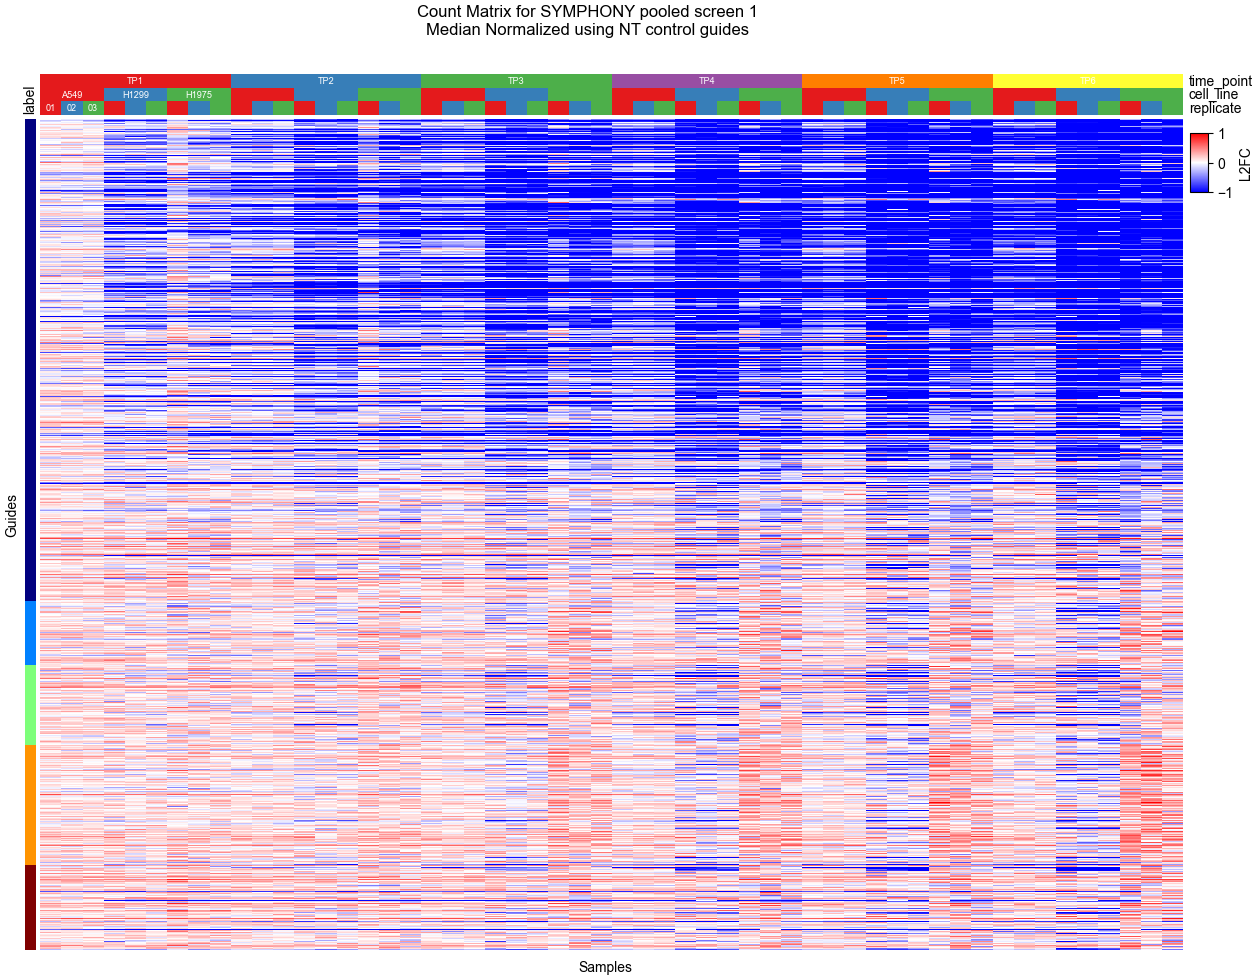

In [41]:
import PyComplexHeatmap as pch
data = df.loc[:, sample_names_wo_pools]
temp = data.T
temp['time'] = [x.split('-')[-1] for x in temp.index]
temp['replicate'] = [x.split('-')[2] for x in temp.index]
temp['cell_line'] = [cell_line_dict[x.split('-')[1]] for x in temp.index]
data = temp.sort_values(['time', 'cell_line', 'replicate']).drop(['time', 'replicate', 'cell_line'], axis=1).T

cell_line = pd.Series({x: x.split('-')[1] for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})

top_ha = pch.HeatmapAnnotation(
    time_point=pch.anno_simple(time_point, add_text=True),
    cell_line=pch.anno_simple(cell_line, add_text=True),
    replicate=pch.anno_simple(replicate, add_text=True),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_simple(scores.label, legend=False),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, legend_gap=7,
    rasterized=True, cmap='bwr', vmin=-1, vmax=1,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('Count Matrix for SYMPHONY pooled screen 1\nMedian Normalized using NT control guides', y=0.95)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap.png', dpi=300)
pl.show()